# CV2  Sobel, Canny, Harries, 直方图均衡化

## 本次作业主要分为四个部分：
###     1. 准备工作
###     2. 实现Canny边缘检测
###     3. 实现Harries角点检测
###     4. 直方图均衡化

In [1]:
# 引入库函数
import sys
from itertools import accumulate

import cv2
import numpy as np
import matplotlib.pyplot as plt
from numpy.ma.core import zeros_like

print(sys.executable)
print(cv2.__version__)

/home/zhangjuntao/projects/opencv-homework1/.venv/bin/python
5.0.0


In [2]:
from pathlib import Path
project_dir = Path.cwd()
image_dir = project_dir / "image"
result_dir = project_dir / "result"

result_dir.mkdir(parents=True, exist_ok=True)

### **Step1: 准备工作**

### 准备工作主要包括以下3步：
####    1. 将原图处理成灰度图
####    2. 实现用高斯滤波对图片进行滤波（$size = 5, \sigma = 1$）
####    3. 实现Sobel, 并对上一步处理之后的图像进行差分（先进行padding）

In [3]:
image_path = image_dir / "input.jpeg"
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
gray = image.astype(np.float64)

print(gray.shape)
print(gray.dtype)

(400, 400)
float64


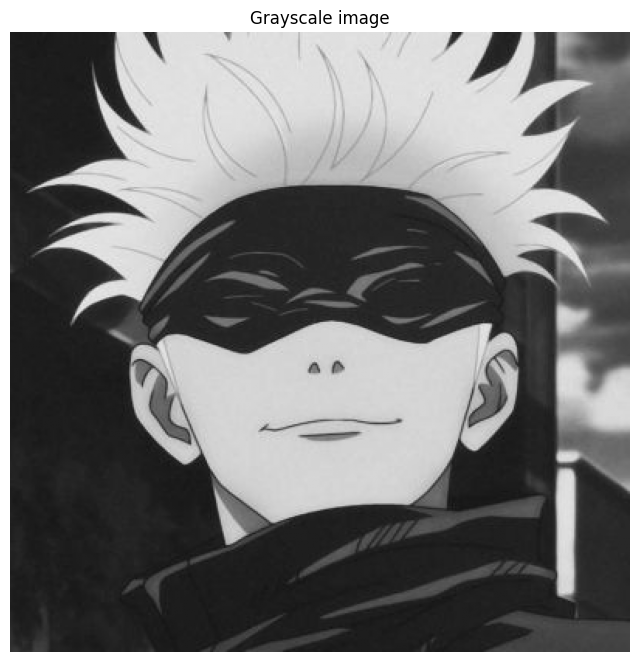

In [4]:
fig, ax = plt.subplots(figsize=(8, 10))
ax.imshow(gray, cmap='gray', vmin = 0, vmax = 255)
ax.axis("off")
ax.set_title("Grayscale image")
plt.savefig(result_dir / "Grayscale_image", dpi=200, bbox_inches='tight')
plt.show()

#### 接下来，先对图片进行高斯滤波

#### 沿用cv1中实现的copyEdge作为Padding

In [5]:
def copyEdge(gray, k): # k = size // 2
    m, n = gray.shape
    edgeCopied = np.zeros((m + 2*k, n + 2*k), dtype = np.float64)
    edgeCopied[k:(m + k), k:(n + k)] = gray

    # 先复制四个角
    for i in range(k):
        for j in range(k):
            edgeCopied[i][j] = gray[0][0]
            edgeCopied[i][n + k + j] = gray[0][n - 1]
            edgeCopied[m + k + i][j] = gray[m - 1][0]
            edgeCopied[m + k + i][n + k + j] = gray[m - 1][n - 1]

    # 再复制四条边
    for i in range(k):
        edgeCopied[k:(m + k) , i] = gray[:, 0]
        edgeCopied[k:(m + k), n + k + i] = gray[:, n - 1]
        edgeCopied[i, k:(n + k)] = gray[0, :]
        edgeCopied[m + k + i, k:(n + k)] = gray[m - 1, :]
    return edgeCopied

#### 修改cv1中的filter函数

In [6]:
def filter(gray, kernel):
    m, n = gray.shape
    size = kernel.shape[0]
    copyEdged = copyEdge(gray, size // 2)
    grayFilter = np.zeros((m, n), dtype = np.float64)
    for i in range(m):
        for j in range(n):
            patch = copyEdged[i:i + size, j:j + size]
            grayFilter[i][j] = np.sum(patch * kernel)
    return grayFilter

#### 调用opencv库得到一个$size = 5, \sigma = 1$的高斯核， 并对灰度图进行高斯滤波

In [7]:
g = cv2.getGaussianKernel(5, 1)
cvKernel = g @ g.T

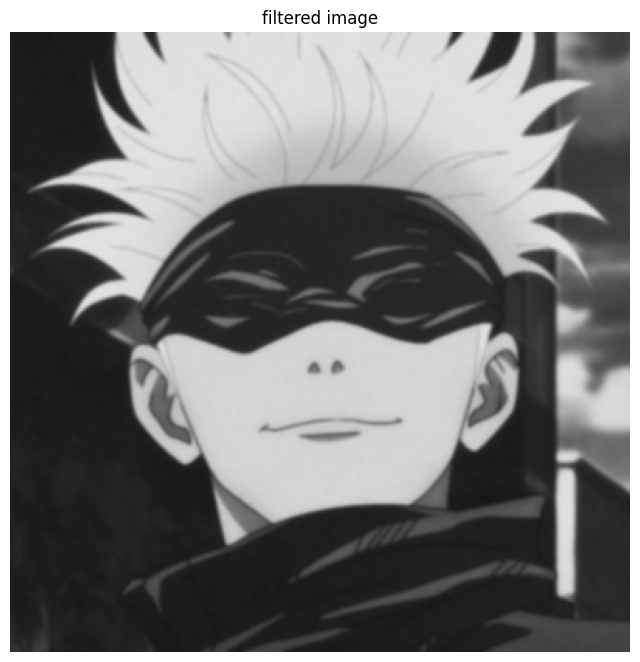

In [8]:
gray = filter(gray, cvKernel)
fig, ax = plt.subplots(figsize=(8, 10))
ax.imshow(gray, cmap='gray', vmin = 0, vmax = 255)
ax.axis("off")
ax.set_title("filtered image")
save_path = result_dir / "filtered.jpeg"
plt.savefig(save_path, dpi=200, bbox_inches='tight')
plt.show()

#### 然后实现Sobel核，对gray进行滤波，得到其梯度Gx, Gy

In [9]:
vectorX = np.array([[-1, 0, 1]], dtype = np.float64)
vectorY = np.array([[1, 2, 1]], dtype = np.float64)
sobelX = vectorY.T @ vectorX
sobelY = sobelX.T
print(sobelX)
print(sobelY)

[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]


In [10]:
Gx = filter(gray, sobelX)
Gy = filter(gray, sobelY)
print(Gx.shape)

(400, 400)


#### 绘制红蓝图来展示梯度Gx和Gy的分布情况

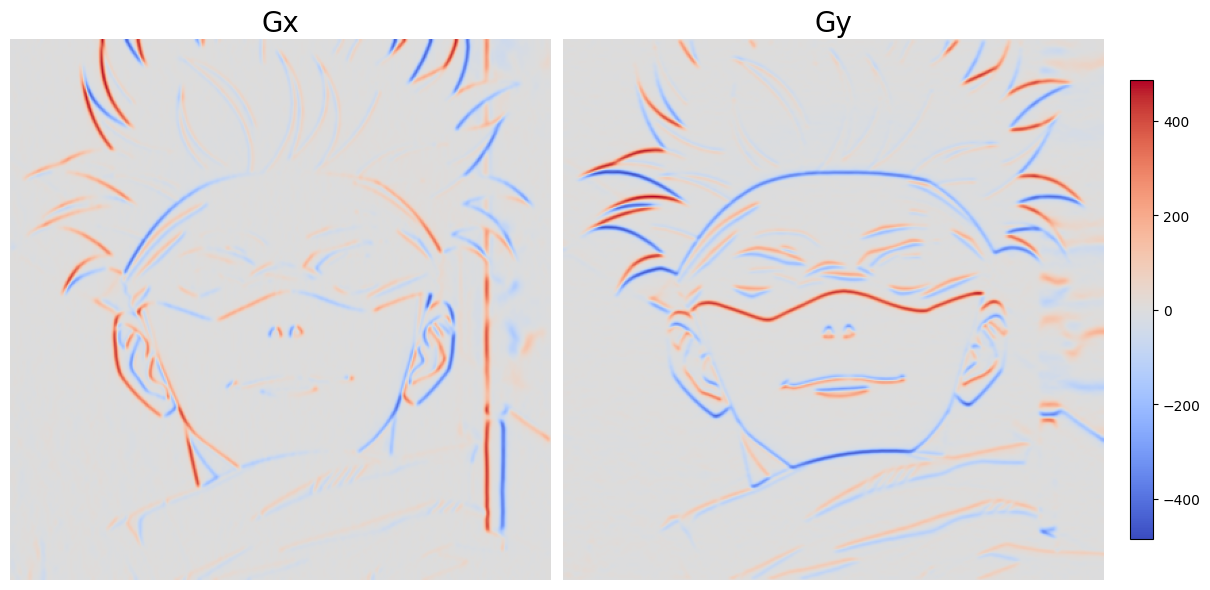

In [11]:
# 两张图公用一个颜色范围，方便对比
vmax = max(np.abs(Gx).max(), np.abs(Gy).max())
fig, axes = plt.subplots(1, 2, figsize = (12, 6), layout = "constrained")

image_x = axes[0].imshow(Gx, cmap = 'coolwarm', vmin = -vmax, vmax = vmax)
axes[0].set_title("Gx", fontsize = 20)
axes[0].axis("off")
image_y = axes[1].imshow(Gy, cmap = 'coolwarm', vmin = -vmax, vmax = vmax)
axes[1].set_title("Gy", fontsize = 20)
axes[1].axis("off")

fig.colorbar(image_y, ax = axes[1], shrink = 0.8)
fig.savefig(result_dir / "Sobel_gradients.png", dpi=200, bbox_inches='tight')
plt.show()

### **Step2: 实现Canny边缘检测**

### 实现Canny主要包括以下4步：
####    1. 利用Gx, Gy计算出梯度大小magnitude和方向direction, 再将方向转为[0, 180]度的angle
####    2. 实现NMS
####    3. 利用双阀值对NMS之后的点作进一步筛选
####    4. 将最终剩下的点用BFS连起来

In [12]:
# 计算magnitude和angle
magnitude = np.hypot(Gx, Gy)
direction = np.arctan2(Gy, Gx)
angle = np.degrees(direction) % 180 #将角度限制在【0, 180】，方便后面划归为四个方向做NMS

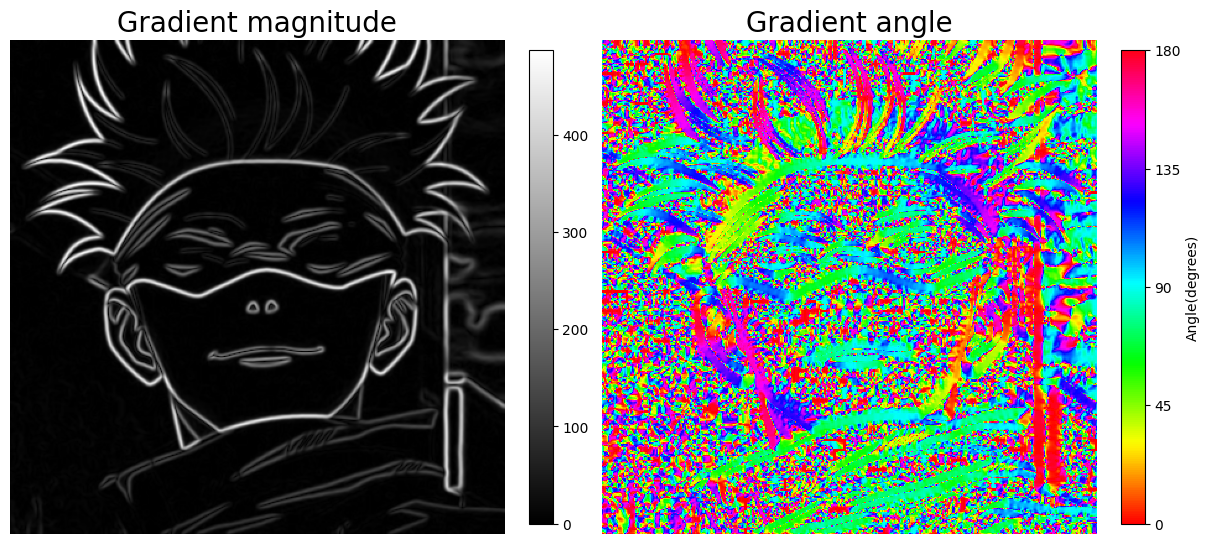

In [13]:
fig, axes = plt.subplots(1, 2, figsize = (12, 6), layout = "constrained")
# 梯度越小，变化越小，其对应的灰度值越大
image_magnitude = axes[0].imshow(magnitude, cmap = "gray", vmin = 0)
axes[0].set_title("Gradient magnitude", fontsize = 20)
axes[0].axis("off")
fig.colorbar(image_magnitude, ax = axes[0], shrink = 0.8)
# 角度对应色条的颜色
image_angle = axes[1].imshow(angle, cmap = "hsv", vmin = 0, vmax = 180, interpolation = "nearest")
axes[1].set_title("Gradient angle", fontsize = 20)
axes[1].axis("off")
fig.colorbar(image_angle, ax = axes[1], shrink = 0.8, ticks = [0, 45, 90, 135, 180], label = "Angle(degrees)")
fig.savefig(result_dir / "magnitude_angle.png", dpi=200, bbox_inches='tight')
plt.show()

#### 接下来实现NMS

#### 先实现一个将所给角度划归到四个方向上的辅助函数dxdy

In [14]:
# 返回一个二维数组，表示该点需要对比magnitude的一个相邻点相对于该点的位置
def dxdy(angle):
    if angle <= 22.5 or angle > 157.5:
        return 0, 1
    elif angle > 22.5 and angle <= 67.5:
        return 1, 1
    elif angle > 67.5 and angle <= 112.5:
        return 1, 0
    else:
        return 1, -1

#### 再实现NMS

In [15]:
# 实现NMS,这里只处理内部的点（防止越界）
def NMS(magnitude, angle):
    m, n = magnitude.shape
    NMS = np.zeros_like(magnitude, dtype = np.float64)
    for y in range(1, m - 1):
        for x in range(1, n - 1):
            dy, dx = dxdy(angle[y][x])
            if magnitude[y][x] >= magnitude[y + dy][x + dx] and magnitude[y][x] >= magnitude[y - dy][x - dx]:
                NMS[y][x] = magnitude[y][x]
    return NMS

In [16]:
nms = NMS(magnitude, angle)

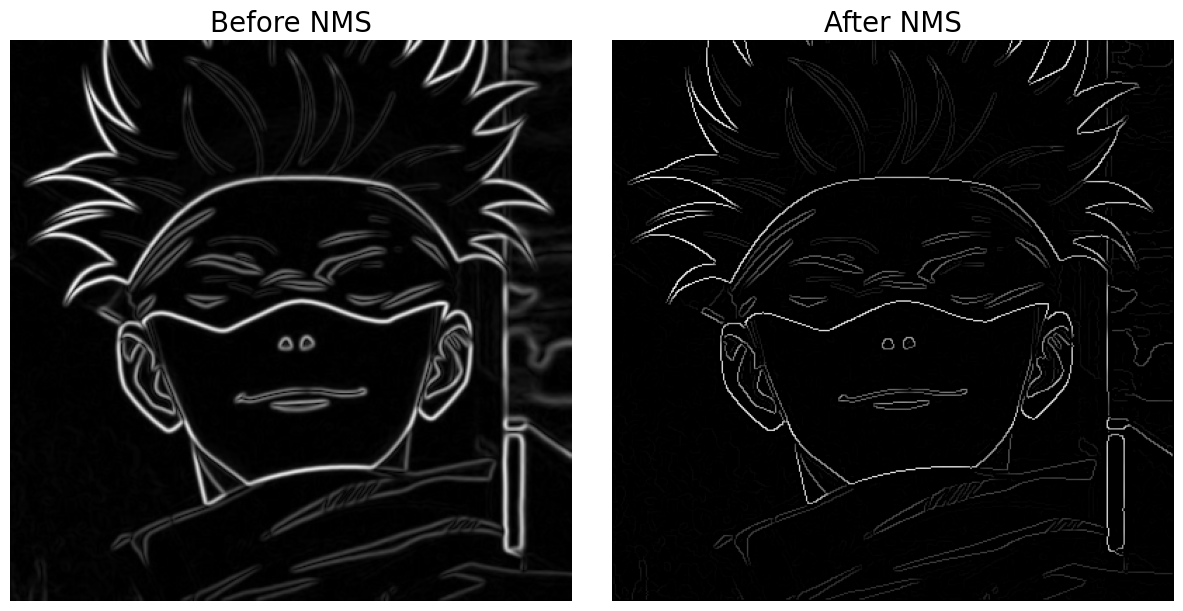

In [17]:
# 将magnitude和nms放在一起对比
vmax = magnitude.max()
fig, axes = plt.subplots(1, 2, figsize = (12, 6), layout = "constrained")
axes[0].imshow(magnitude, cmap = "gray", vmin = 0, vmax = vmax)
axes[0].set_title("Before NMS", fontsize = 20)
axes[0].axis("off")
axes[1].imshow(nms, cmap = "gray", vmin = 0, vmax = vmax)
axes[1].set_title("After NMS", fontsize = 20)
axes[1].axis("off")
fig.savefig(result_dir / "nms_comparison.png", dpi=200, bbox_inches='tight')
plt.show()

#### 再利用双阀值TL, TH对nms做进一步处理

In [18]:
def tLH(TL, TH, nms):
    strong = nms >= TH
    weak = (nms >= TL) & (nms < TH)
    return strong, weak

In [19]:
# 这里暂时令Th = 100, TL = 30
strong, weak = tLH(30, 100, nms)

In [20]:
# 将strong设为255, weak设为100
threshold = np.zeros_like(nms, dtype = np.float64)
threshold[weak] = 100
threshold[strong] = 255

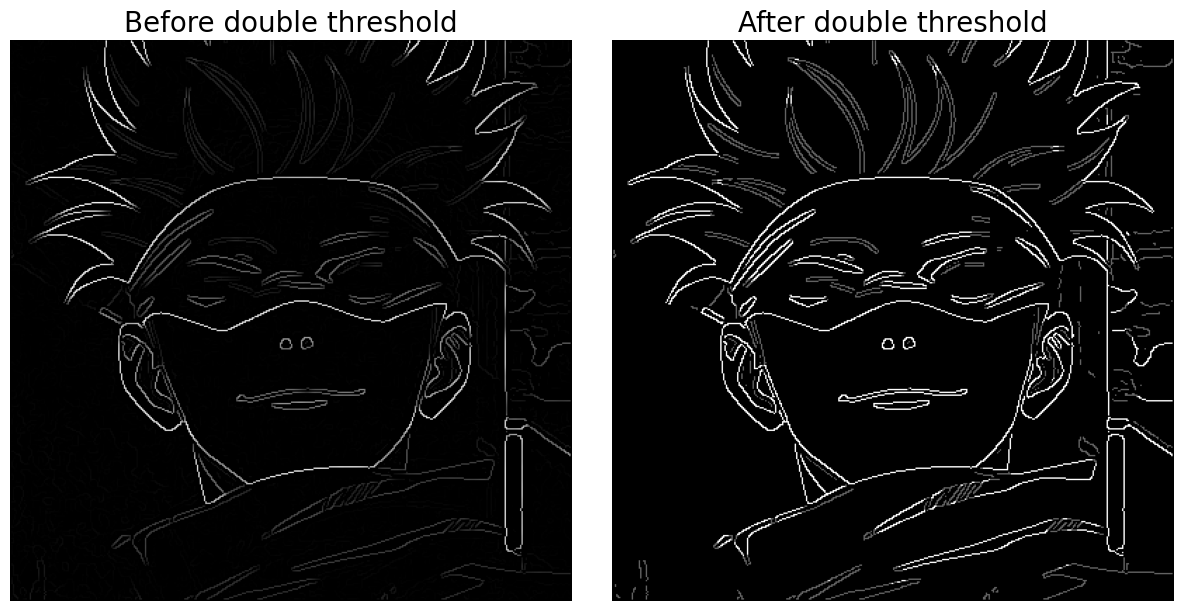

In [21]:
# 将双阀值处理之后的threshold和nms对比展示
fig, axes = plt.subplots(1, 2, figsize = (12, 6), layout = "constrained")
axes[0].imshow(nms, cmap = "gray", vmin = 0)
axes[0].set_title("Before double threshold", fontsize = 20)
axes[0].axis("off")
axes[1].imshow(threshold, cmap = "gray", vmin = 0, vmax = 255)
axes[1].set_title("After double threshold", fontsize = 20)
axes[1].axis("off")
fig.savefig(result_dir / "double_threshold.png", dpi=200, bbox_inches='tight')
plt.show()

#### 最后，我们需要实现BFS，来把strong以及能和strong连通的weak都选作边缘显示

In [22]:
# 主体思路和CS61B中实现的BFS思路一致。建一个Queue来动态储存需要加入边缘的点。先将所有strong的点加入这个queue，并将他们的isAdded改为True
from collections import deque
queue = deque((int(y), int(x)) for y, x in np.argwhere(strong))
isAdded = np.zeros_like(strong, dtype = np.bool)
isAdded[strong] = True
# 然后我们每次都把queue的第一个元素取出来，把他周围的isAdded = False的weak点都加入到这个queue中，如此循环直到queue为空
m, n = strong.shape
while queue:
    y, x = queue.popleft()
    for dy in [-1, 0, 1]:
        for dx in [-1, 0, 1]:
            if dx == 0 and dy == 0:
                continue
            ny = y + dy
            nx = x + dx
            if nx < 0 or nx > n - 1 or ny < 0 or ny > m - 1:
                continue
            if weak[ny][nx] and not isAdded[ny][nx]:
                isAdded[ny][nx] = True
                queue.append((ny, nx))

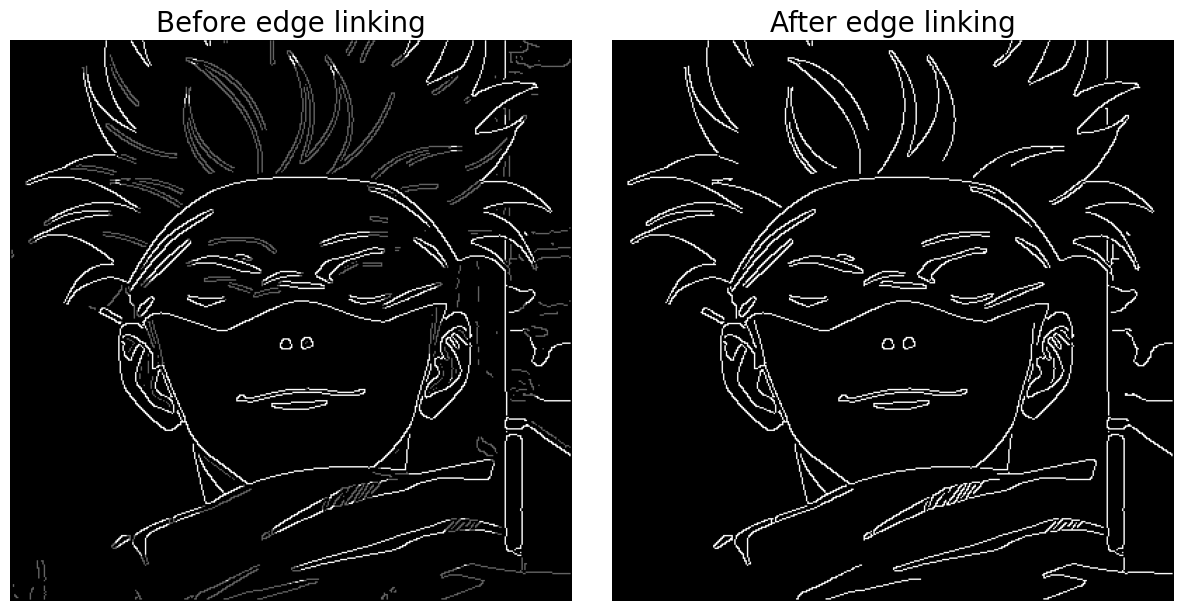

In [23]:
# 将double threshold之后的图片和edge linking后的图片对比展示
fig, axes = plt.subplots(1, 2, figsize = (12, 6), layout = "constrained")
# 左边是双阀值分类图。strong为255, weak为100
axes[0].imshow(threshold, cmap = "gray", vmin = 0, vmax = 255)
axes[0].set_title("Before edge linking", fontsize = 20)
axes[0].axis("off")
# 右边是使用BFS进行连接边缘后的黑白图像, True为白色，False为黑色
axes[1].imshow(isAdded, cmap = "gray", vmin = 0, vmax = 1)
axes[1].set_title("After edge linking", fontsize = 20)
axes[1].axis("off")
fig.savefig(result_dir / "edge_linking.png", dpi=200, bbox_inches='tight')
plt.show()

### **Step3: 实现Harries角点检测**

### 在实现了Canny的基础上，实现Harries主要分为以下四步：
####    1. 准备Gx2, Gy2, Gxy，用不同尺寸的高斯滤波核对他们进行滤波，得到三组A, B, C和他们对应的response
####    2. 用阀值对response进行筛选，得到candidates
####    3. 将在自己的邻域内最大的candidates选出来，作为corners（选取三组不同大小的邻域）

#### 先写一个得到不同尺寸的高斯核的辅助函数(使用opencv库， 且默认$\sigma = 1$)

In [24]:
def kernelHelper(size): # sigma默认为1
    g = cv2.getGaussianKernel(size, 1)
    kernel = g @ g.T
    return kernel

#### 再利用之前得到的梯度Gx, Gy计算Gx2, Gy2, Gxy

In [25]:
Gx2 = Gx * Gx
Gxy = Gx * Gy
Gy2 = Gy * Gy

#### 用$size \in \{ 3, 5, 7 \}$的高斯核对得到的Gx2, Gy2, Gxy进行滤波得到A，B，C，并分别计算得到三组response(这里将响应系数设为0.04)

In [26]:
responses = {}
for size in [3, 5, 7]:
    kernel = kernelHelper(size)
    A = filter(Gx2, kernel)
    B = filter(Gxy, kernel)
    C = filter(Gy2, kernel)
    response = A * C - B * B - 0.04 * (A + C) ** 2
    responses[size] = response

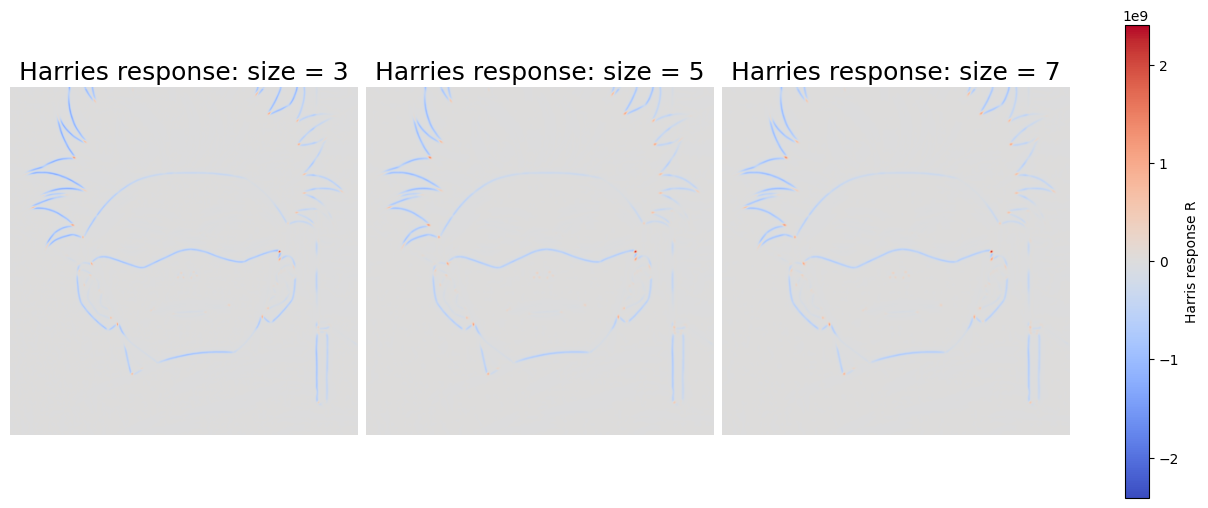

In [27]:
vmax = max(np.max(abs(response)) for response in responses.values())
response3 = responses[3]
response5 = responses[5]
response7 = responses[7]
fig, axes = plt.subplots(1, 3, figsize = (12, 6), layout = "constrained")
image3 = axes[0].imshow(response3, cmap = "coolwarm", vmin = -vmax, vmax = vmax)
axes[0].set_title("Harries response: size = 3", fontsize = 18)
axes[0].axis("off")
image5 = axes[1].imshow(response5, cmap = "coolwarm", vmin = -vmax, vmax = vmax)
axes[1].set_title("Harries response: size = 5", fontsize = 18)
axes[1].axis("off")
image7 = axes[2].imshow(response7, cmap = "coolwarm", vmin = -vmax, vmax = vmax)
axes[2].set_title("Harries response: size = 7", fontsize = 18)
axes[2].axis("off")
fig.colorbar(image7, ax = axes, shrink = 0.8, label = "Harris response R")
fig.savefig(result_dir / "harris_responses.png", dpi=200, bbox_inches='tight')
plt.show()

#### 然后，我们将每个response最大值的0.01倍作为阀值，筛选response得到candidates

In [28]:
candidates = {}
for size in [3, 5, 7]:
    response = responses[size]
    max_response = response.max()
    minimum = 0.01 * max(0.0, max_response)
    candidate = response > minimum
    candidates[size] = candidate

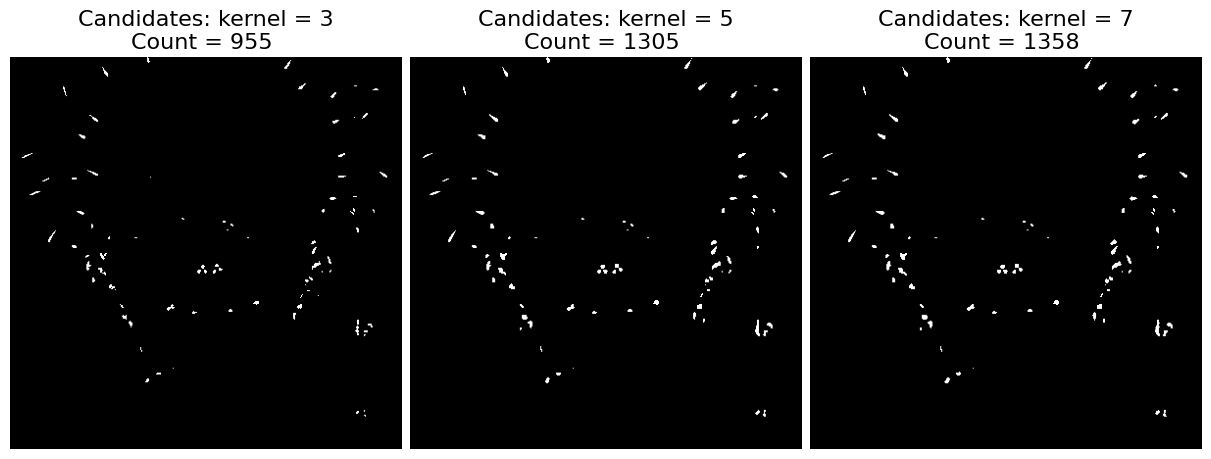

In [29]:
# 白色是通过阀值筛选的位置
fig, axes = plt.subplots(1, 3, figsize = (12, 6), layout = "constrained")
sizes = [3, 5, 7]
for i in range(3):
    size = sizes[i]
    candidate = candidates[size]
    axes[i].imshow(candidate, cmap = "gray", vmin = 0, vmax = 1)
    axes[i].set_title(f"Candidates: kernel = {size}\n"
                      f"Count = {candidate.sum()} ", fontsize = 16)
    axes[i].axis("off")
fig.savefig(result_dir / "harries_candidates.png", dpi=200, bbox_inches='tight')
plt.show()

#### 最后，我们选取$size \in \{ 3, 9, 15 \}$的邻域来做NMS，得到角点的坐标集合corners

In [30]:
corners = {}
for kernel_size in [3, 5, 7]:
    for nms_size in [3, 9, 15]:
        response = responses[kernel_size]
        candidate = candidates[kernel_size]
        h, w = response.shape
        k = nms_size // 2
        corner = np.zeros_like(response, dtype = np.bool)
        for y in range(k, h - k):
            for x in range(k, w - k):
                if not candidate[y][x]:
                    continue
                patch = response[y - k: y + k + 1, x - k: x + k + 1]
                if response[y][x] == np.max(patch):
                    corner[y][x] = True
        corners[(kernel_size, nms_size)] = corner

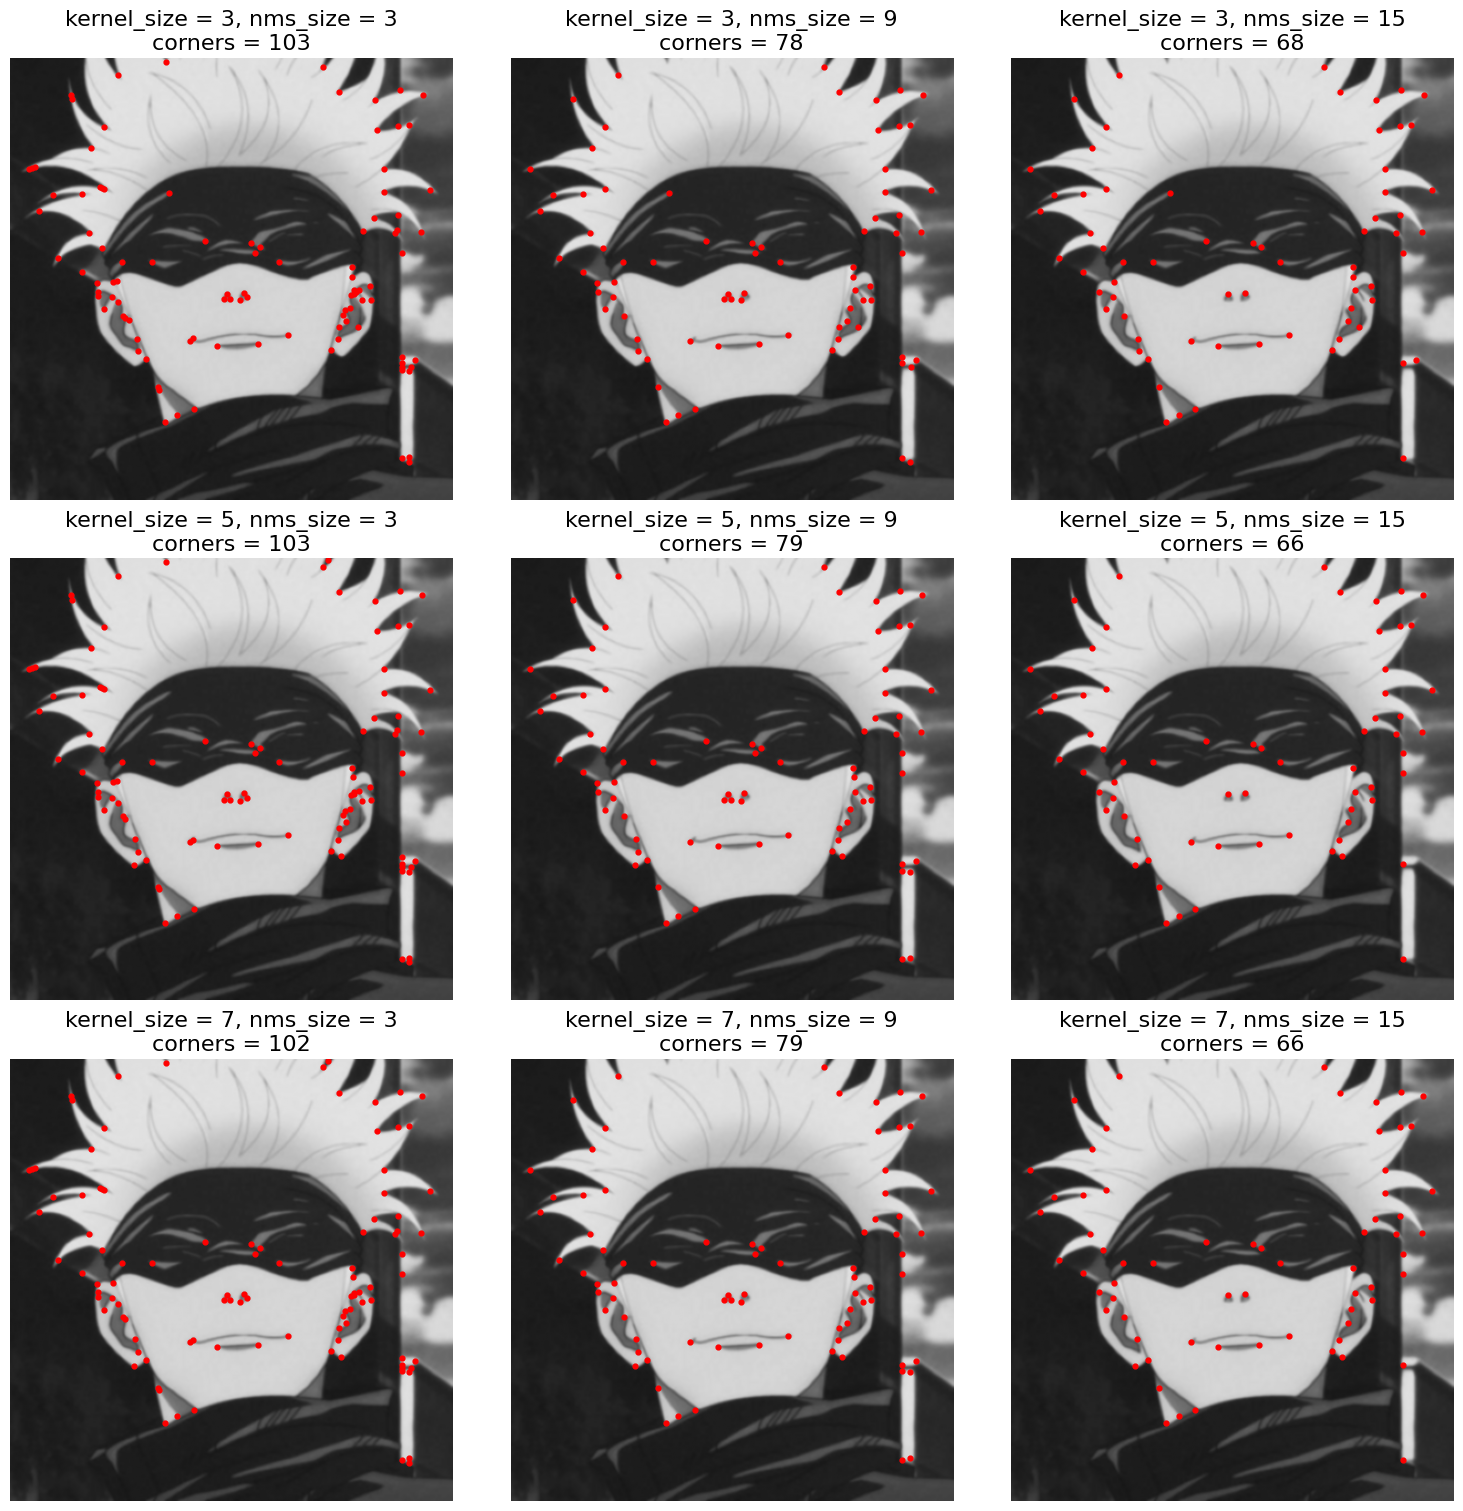

In [31]:
# 每行固定高斯核大小, 每列固定NMS邻域大小
fig, axes = plt.subplots(3, 3, figsize = (15, 15), layout = "constrained")
kernel_sizes = [3, 5, 7]
nms_sizes = [3, 9, 15]

for row in range(3):
    for col in range(3):
        kernel_size = kernel_sizes[row]
        nms_size = nms_sizes[col]
        corner = corners[(kernel_size, nms_size)]
        # 找出所有角点的坐标
        ys, xs = np.where(corner)
        # 先画灰度图，再叠加红点
        axes[row, col].imshow(gray, cmap = "gray", vmin = 0, vmax = 255)
        axes[row, col].scatter(xs, ys, c = "red", s = 12)
        axes[row, col].set_title(f"kernel_size = {kernel_size}, nms_size = {nms_size}\n"
                                 f"corners = {len(xs)}", fontsize = 16)
        axes[row, col].axis("off")
fig.savefig(result_dir / "harries_corners.png", dpi=200, bbox_inches='tight')
plt.show()

#### 在固定高斯窗口时，增大NMS邻域会减少保留角点的数量，使角点分布更加稀疏。主要角点位置相对稳定，但其周围的较弱响应峰则会被更多地抑制。
#### 另外，这里的实现会跳过图像边界，因此邻域增大时，边界附近参与检测的范围也会减小（可能导致边界处角点的遗漏）

### **Step4: 直方图均衡化**

### 直方图均衡化和前面两个人物基本独立，完成它主要分为3步：
####    1. 统计灰度照片中每种灰度值的出现次数
####    2. 计算灰度值出现次数的累计次数
####    3. 通过T(v)函数得到新的灰度值大小

In [32]:
# 读取原图，并转化为灰度图像
gray = cv2.imread("image/input.jpeg", cv2.IMREAD_GRAYSCALE)

#### 首先，实现calculate_hist函数，接受灰度图像并返回一个hist数组，记录每个灰度值的像素个数

In [33]:
def calculate_hist(image):
    hist = np.zeros(256)
    m, n = image.shape
    for y in range(m):
        for x in range(n):
            hist[image[y][x]] += 1
    return hist

In [34]:
hist = calculate_hist(gray)

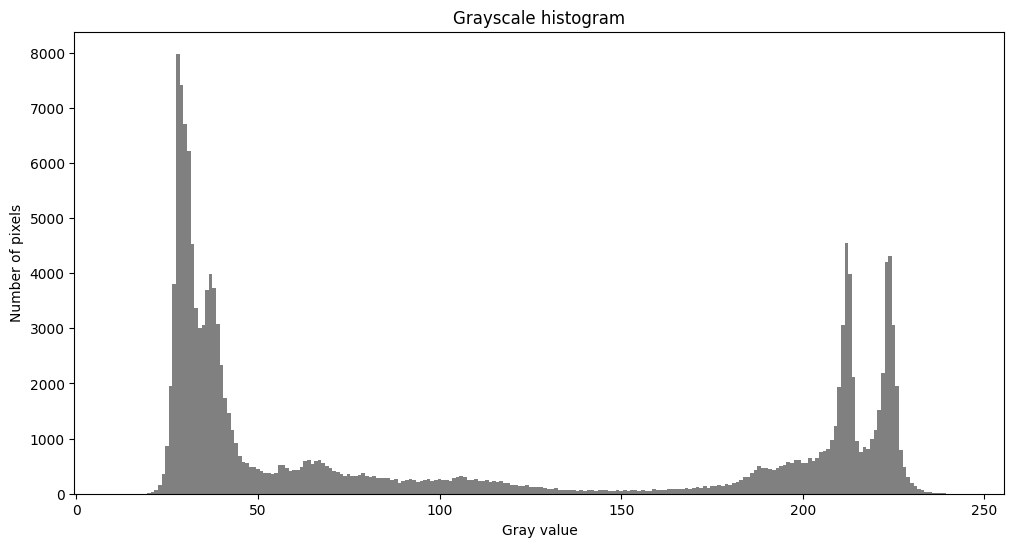

In [35]:
fig, ax = plt.subplots(figsize = (12, 6))
ax.bar(range(256), hist, width = 1, color = "gray")
ax.set_title("Grayscale histogram")
ax.set_xlabel("Gray value")
ax.set_ylabel("Number of pixels")
ax.set_xlim(-0.5, 255.5)
fig.savefig(result_dir / "histogram.png", dpi=200, bbox_inches='tight')
plt.show()

#### 接下来统计累计次数accumulate

In [36]:
accumulate = np.zeros_like(hist)
total = 0
for value in range(256):
    total += hist[value]
    accumulate[value] = total

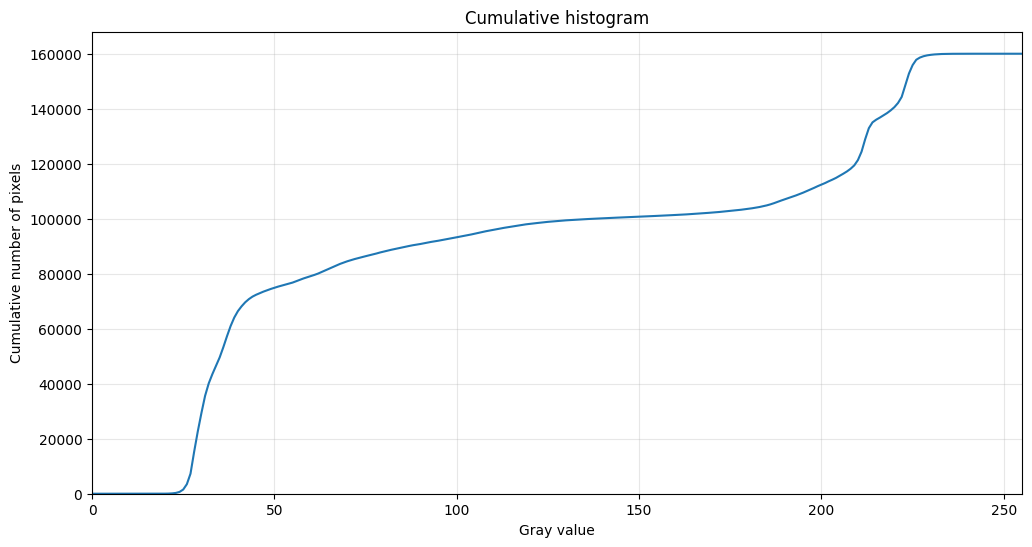

In [37]:
fig, ax = plt.subplots(figsize = (12, 6))
ax.plot(range(256), accumulate)
ax.set_title("Cumulative histogram")
ax.set_xlabel("Gray value")
ax.set_ylabel("Cumulative number of pixels")
ax.set_xlim(0, 255)
ax.set_ylim(bottom = 0)
ax.grid(alpha = 0.3)
fig.savefig(result_dir / "accumulate.png", dpi=200, bbox_inches='tight')
plt.show()

#### 最后，利用公式

\begin{equation}
    T(v) = round \left[ 255 * \frac{C(v) - C_{min}}{N - C_{min}} \right],
    \quad C_{min}表示accumulate的最小非零元素
\end{equation}

#### 计算出均衡化之后原灰度值对应的新灰度值。

In [38]:
cMin = min(num for num in accumulate if num > 0) # 找出C_min
lookup = np.zeros(256, dtype = np.uint8) # 建立从原来的灰度值到新的灰度值的映射
n = gray.size
if cMin == n: # 若全图只有一种灰度就返回原图
    output = gray.copy()
else:
    for value in range(256):
        new_value = round(255 * (accumulate[value] - cMin) / (n - cMin))
        lookup[value] = max(0, min(255, new_value))
    m, n = gray.shape
    output = np.zeros_like(gray, dtype = np.uint8)
    for y in range(m):
        for x in range(n):
            output[y][x] = lookup[gray[y][x]]

In [39]:
output_hist = calculate_hist(output)

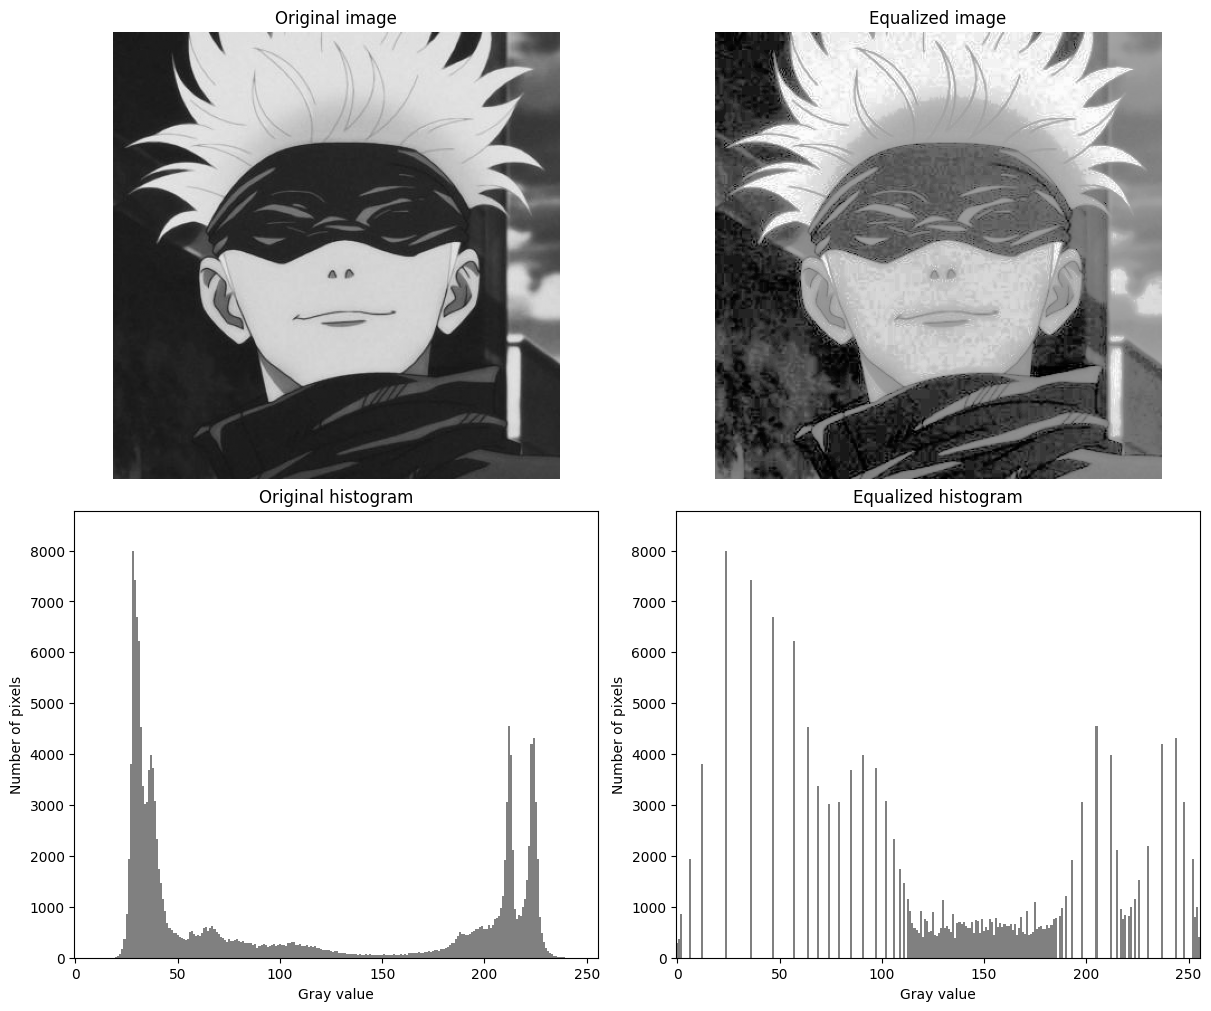

In [40]:
fig, axes = plt.subplots(2, 2, figsize = (12, 10), layout = "constrained")
# 左上为原图
axes[0, 0].imshow(gray, cmap = "gray", vmin = 0, vmax = 255)
axes[0, 0].set_title("Original image")
axes[0, 0].axis("off")
# 右上为均衡之后的图像
axes[0, 1].imshow(output, cmap = "gray", vmin = 0, vmax = 255)
axes[0, 1].set_title("Equalized image")
axes[0, 1].axis("off")
ymax = max(hist.max(), output_hist.max()) * 1.1
# 左下为原图的直方图
axes[1, 0].bar(range(256), hist, width = 1, color = "gray")
axes[1, 0].set_title("Original histogram")
axes[1, 0].set_xlabel("Gray value")
axes[1, 0].set_ylabel("Number of pixels")
axes[1, 0].set_xlim(-0.5, 255.5)
axes[1, 0].set_ylim(0, ymax)
# 右下为均衡化之后的直方图
axes[1, 1].bar(range(256), output_hist, width = 1, color = "gray")
axes[1, 1].set_title("Equalized histogram")
axes[1, 1].set_xlabel("Gray value")
axes[1, 1].set_ylabel("Number of pixels")
axes[1, 1].set_xlim(-0.5, 255.5)
axes[1, 1].set_ylim(0, ymax)
fig.savefig(result_dir / "equalization_comparison.png", dpi=200, bbox_inches='tight')
plt.show()

#### 总的来说，均衡化之后灰度分布地更宽了，原本较暗的区域的细节更加明显了。
#### **但是，背景的噪声，纹理也被增强了！**
#### 输出的直方图仍有尖峰和空隙，这是因为相同灰度的像素会被映射到相同的新灰度上。均衡化并不能保证每个灰度的像素数量相等。